:::{list-table}
:header-rows: 1
:align: center
:widths: 90 10
* - #
    # Fondamenti di programmazione
    # Canale A-L - Prof. M. Mancini
    # AA 26-27 - Lezione 11
    
  - :::{image}attachment:5a837f06-202c-4c6e-9259-dd7a6dc01c97.png
    :width: 200px
    :::
:::

In [1]:
#%load_ext nb_mypy

# RECAP:
- Colori come oggetti (con matematica dei colori)
- Immagini come matrici di Colori
- Filtri come oggetti che generano il colore del nuovo pixel
- Figure geometriche come oggetti con metodi di disegno


# METODOLOGIA di analisi Object Oriented 
- Si individuano le strutture dati necessarie (**class**)
- con i loro **attributi** (informazioni "personali" di ciascun dato)
  - se una informazione è identica e comune a tutti gli individui la posso mettere come **attributo di classe**
- si definisce la loro inizializzazione (**`__init__`**) con gli argomenti necessari
- i **metodi** fondamentali (operazione sui dati o che calcolano valori a partire dagli attributi)
  - se vogliamo creare l'oggetto in altri modi possiamo definire un **@classmethod**

Ogni volta che vogliamo aggiungere una funzionalità ci dobbiamo chiedere 
quale oggetto deve essere "responsabile" (oppure "conosce le informazioni") per calcolarla

**Metafora dell'ufficio**
- E' un po' come voler organizzare un ufficio con persone che hanno **tipi di mansioni** diverse
  - ciascuno ha le sue informazioni e si cerca di non assegnarle a più uffici (classi)
  - gli scambi tra impiegati devono essere minimi



# Ereditarietà (Specializzazione/ Riuso e Ampliamento delle funzionalita)
Se si vede che diverse classi condividono dei comportamenti/attributi comuni
- definiamo una super-classe che contiene l'implementazione comune dei metodi o gli attributi comuni
- nelle sottoclassi che ereditano da questa mettiamo solo gli attributi diversi ed i metodi diversi
   - per chiamare i metodi della superclasse si usa **`super().metodo(argomenti)`**

Esempio: tutti gli animali visualizzati in un gioco hanno una posizione, una icona, un verso ...
 l'insieme degli attributi e metodi comuni può essere messo nella classe Animale
 da cui ereditano Cane, Gatto, Cavallo, Ornitorinco ....

# Esempio: Una gerarchia di figure realizzata con TURTLE graphics
Usiamo la libreria **turtle** che ci permette di disegnare sullo schermo con comandi semplici

In [2]:
from pygraphviz import AGraph
G = AGraph(directed=True, rankdir='TD')
G.edge_attr['dir'] = 'back'
G.add_node('Figura',label='Figura\nattributi: posizione e colore\nmetodi: draw(), move() e area()')
G.add_node('PoligonoRegolare',label='PoligonoRegolare\nattributi: N')
G.add_node('Rettangolo',label='Rettangolo\nlarghezza e altezza')
G.add_nodes_from(['Punto','Linea','Freccia','Ellisse\nApprossimata\nDaCerchi','Cerchio',
                  'Triangolo\nRettangolo'],style='dotted')
G.add_edges_from([('Figura','Punto'),('Figura','Linea'),('Figura','PoligonoRegolare'),
    ('Figura','Rettangolo'),('Figura','Ellisse\nApprossimata\nDaCerchi'),
    ('Linea','Freccia'),('Rettangolo','Quadrato'),('PoligonoRegolare','Pentagono'),
    ('Rettangolo','Triangolo\nRettangolo'),('Ellisse\nApprossimata\nDaCerchi','Cerchio'),])
G.add_edge('PoligonoRegolare','Quadrato', style='dotted')
G.layout('dot')

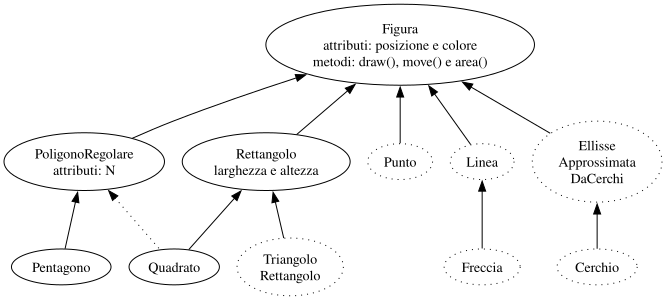

In [3]:
G

In [4]:
# Tutte le Figure hanno:
# - posizione
# - colore
# - un metodo che le disegna (che per default non fa nulla)
# - un metodo che ne calcola l'area (per default 0)

# Ciascuna specifica figura
# - ha dei parametri specifici (raggio, lati, cateti, fuochi, retta e fuoco, ...)
# - ha il suo metodo specifico che la disegna
# - ha il suo metodo specifico che ne calcola l'area

# definiamo la gerarchia di classi: 
# Figura
#   Punto
#   Linea
#       Freccia
#   Rettangolo
#       Quadrato
#       TriangoloRettangolo
#   PoligonoRegolare
#       Triangolo
#       Pentagono
#   EllisseApprossimataDaCerchi
#       Cerchio

In [44]:
import turtle
t = turtle.Turtle()
turtle.colormode(255)

## Una Figura ha posizione, direzione, spessore, colore, campitura
- deve calcolare l'area
- deve sapersi disegnare
- la si può spostare

In [46]:
class Figura:
    def __init__(self, x, y, colore, direzione=0, spessore=1, campitura=None):
        self._x = x
        self._y = y
        self._colore = colore
        self._direzione = direzione
        self._spessore = spessore
        self._campitura = campitura

    def area(self):
        "metodo da implementare nelle sottoclassi"
        raise NotImplementedError("Il metodo 'area' non è stato implementato")

    def draw(self, turtle):
        """ 
        setup iniziale che temina le operazioni precedenti, si posiziona nel punto giusto
        setta direzione, dimensione della penna, colore della linea e colore di riempimento
        """
        turtle.end_fill()
        turtle.up()
        turtle.goto(self._x,self._y)
        turtle.setheading(self._direzione)
        turtle.color(self._colore)
        turtle.pensize(self._spessore)
        turtle.down()
        if self._campitura:
            turtle.fillcolor(self._campitura)
            turtle.begin_fill()
        
    def move(self, x, y):
        "per spostarsi basta cambiare la posizione"
        self._x = x
        self._y = y

In [7]:
#help(turtle)

## Un Rettangolo è una Figura con larghezza ed altezza

In [48]:
        
class Rettangolo(Figura):
    def __init__(self, x, y, colore, larghezza, altezza, 
                 direzione=0, spessore=1, campitura=None):
        "creo un nuovo rettangolo"
        # riuso l'inizializzazione della mia superclasse per
        # gli attributi che già sa gestire
        super().__init__(x, y, colore, direzione, spessore, campitura)
        # gestisco qui gli attributi aggiuntivi
        self._larghezza = larghezza
        self._altezza = altezza

    def area(self):
        "calcolo l'area del rettangolo"
        return self._larghezza * self._altezza

    def draw(self, turtle):  
        """
        Disegno il rettangolo con la tartaruga fornita come parametro.
        """
        super().draw(turtle)
        turtle.forward(self._larghezza)
        turtle.left(90)
        turtle.forward(self._altezza)
        turtle.left(90)
        turtle.forward(self._larghezza)
        turtle.left(90)
        turtle.forward(self._altezza)
        turtle.left(90)
        turtle.end_fill()

## un Quadrato è un Rettangolo con lati uguali

In [49]:
class Quadrato(Rettangolo):
    "un Quadrato è un Rettangolo con lati uguali"
    def __init__(self, x, y, lato, colore, 
                 direzione=0, spessore=1, campitura=None):
        # delego al Rettangolo di disegnarsi
        super().__init__(x, y, colore, lato, lato, # lati uguali
                         direzione, spessore, campitura )

## Un PoligonoRegolare è una Figura con N lati uguali

In [50]:
import math
class PoligonoRegolare(Figura):
    "Costruisco un poligono regolare"
    def __init__(self, x, y, lato, N, colore, 
                 direzione=0, spessore=1, campitura=None):
        # delego alla Figura l'inizializzazione delle info che sa gestire
        super().__init__(x, y, colore, direzione, spessore, campitura)
        # e gestisco solo gli attributi in più
        self._N = N
        self._lato = lato
        
    def draw(self, turtle):
        # per prima cosa mi posiziono e inizializzo penna e colori
        super().draw(turtle)
        # poi disegno il poligono
        angolo_esterno = 360/self._N         # se N sono i lati
        for _ in range(self._N):             # per N volte           
            turtle.forward(self._lato)       # disegno il lato
            turtle.left(angolo_esterno)      # e svolto a sinistra
        turtle.end_fill()                    # se c'è campitura coloro l'interno
        
    def area(self):
        """area del poligono regolare A=(N*L**2)/(4*tan(pi/N))
            vedi https://it.wikipedia.org/wiki/Poligono_regolare
        """
        N = self._N
        L = self._lato
        return (N*L**2)/(4*math.tan(math.pi/N))

## un Pentagono è un PoligonoRegolare con 5 lati 

In [51]:
class Pentagono(PoligonoRegolare):
    "un Pentagono è un PoligonoRegolare con 5 lati"
    def __init__(self, x, y, lato, colore, direzione=0, spessore=1, campitura=None):
        # delego al PoligonoRegolare di disegnarsi
        super().__init__(x, y, lato, 5, colore, direzione, spessore, campitura)

In [52]:
t.clear()

r = Rettangolo(50, 100, colore=(255,0,0), larghezza=200, altezza=100, 
               direzione=45, spessore=5, campitura=(255,255,0))
p = PoligonoRegolare(-100, -100, lato=50, N=7, colore=(0,0,255), 
                     direzione=20, spessore=4, campitura=(255,0,0) )
q = Quadrato(  100, 100, lato=90, colore=(0,255,0), direzione=-30, spessore=10)
f = Pentagono(-100, 200, lato=50, colore=(0,0,255), direzione=60,  spessore=20)
qq = PoligonoRegolare(-100, 100, lato=50, N=4, colore=(255,0,255), direzione=20, spessore=4)

r.draw(t)

r.move(-200,-100)

r.draw(t)

p.draw(t)

q.draw(t)

f.draw(t)

qq.draw(t)

print('rettangolo',r.area(), 'quadrato',q.area(), 'pentagono',f.area(), 'quadrato',qq.area())

rettangolo 20000 quadrato 8100 pentagono 4301.193501472418 quadrato 2500.0000000000005


In [53]:
t.clear()
t.hideturtle()

## ECCETERA (Linea, Freccia, EllisseApprossimataDaCerchi, Cerchio ...)

# PAUSA

# RICORSIONE E PROBLEMI RICORSIVI

## [i Frattali](https://it.wikipedia.org/wiki/Frattale) (insieme di Mandelbrot)
![mandelbrot.png](mandelbrot.png)

### I frattali sono tra noi
![felci.png](felci.png)

Sono composti da **parti più piccole** che hanno la **stessa struttura del tutto**

### Disegnamo un albero frattale
![albero.png](albero.png)

# cos'è un albero frattale?
- ha un tronco che regge due rami
- i rami sono inclinati a sinistra e a destra del tronco
- ciascun ramo ha la **stressa struttura** di un albero 
  ma leggermente **più piccolo**
- un albero di **livello <= zero è una foglia**

# Problemi e Soluzioni ricorsive

Una funzione **è ricorsiva se chiama se' stessa** (principio di induzione).

## Un <u>problema</u> ammette una soluzione ricorsiva se:
- SAPPIAMO COME <u>rimpicciolire la dimensione</u> del problema da risolvere (**riduzione**)
- esiste almeno un problema che ha una <u>soluzione elementare</u> (**caso base**)
- <u>è sempre possibile</u>, applicando ripetutamente la riduzione, <u>arrivare ad uno dei casi base</u> (**convergenza**)
- SAPPIAMO COME <u>ottenere la soluzione del problema iniziale dalle soluzioni dei sottoproblemi</u> (**composizione**)


## Albero: cerchiamo le proprietà del problema ricorsivo

- Un albero di livello <= 0 è una foglia (cerchietto)        (**caso base**)
- Un albero con N livelli è formato da: (**ricomposizione**)
  - un tronco lungo X
  - un **albero con N-1 livelli** inclinato a sinistra, con tronco 80% di X   (**riduzione**)
  - un **albero con N-2 livelli** inclinato a destra,   con tronco 70% di X   (**riduzione**)
- sottraendo 1 o 2 ad N si arriva sempre ad un valore <= 0 (**convergenza**)
  
Questa è una definizione **ricorsiva**: i due rami sono due alberi! abbiamo **riduzione, caso base, convergenza e ricomposizione**!

Mi serve uno strumento di disegno:
- col modulo **turtle** posso tracciare movimenti relativi alla tartaruga
- col modulo **random** posso generare colori casuali

In [1]:
# Per disegnare un albero frattale uso una tartaruga e dei numeri casuali 
import turtle 
from random import randint     # generatore di interi casuali
turtle.colormode(255)          # setto i colori in modalità RGB
t = turtle.Turtle()            # creo una tartaruga
t.penup()                      # alzo la penna
t.left(90)                     # giro verso l'alto 
t.back(200)                    # mi posiziono in basso
t.pensize(5)                   # con penna cicciotta
t.speed(0)                     # e velocità alta
#help(turtle)                  # see also      (oppure 'pydoc turtle')

## funzione che disegna un albero

In [2]:

def albero(t, tronco, angolo, livelli):
    '''disegno un albero con un certo tronco iniziale e # di livelli
    Argomenti:
        t:       la tartaruga a cui dare i comandi
        tronco:  lunghezza del tronco
        angolo:  inclinazione dei rami rispetto al tronco
        livelli: quanti livelli di rami disegnare
    '''
    if livelli <= 0:       # se caso base
        draw_leaf(t)       # disegno la "foglia"
    else:                  # altrimenti caso ricorsivo
        # disegno il tronco (e mi sposto alla sua fine)
        draw_trunk(t, tronco)
        # mi giro a sinistra
        t.left(angolo)
        # disegno il ramo sinistro, più piccolo 80% e con un livello di meno
        albero(t, tronco * 0.8, angolo, livelli-1)
        # mi giro a destra
        t.right(angolo*2)
        # disegno il ramo destro, più piccolo 70% e con due livelli in meno
        albero(t, tronco * 0.7, angolo, livelli-2)
        # torno nella direzione iniziale
        t.left(angolo)
        # torno alla base del tronco
        t.back(tronco)

In [3]:
# devo definire come disegnare il tronco e la foglia
def draw_trunk(t, lunghezza):
    'Disegno un tratto di colore casuale'
    # cambio colore a caso
    R = randint(100, 200)
    G = randint(100, 200)
    B = randint(100, 200)
    t.color(R,G,B)
    # abbasso la penna
    t.pendown()
    # mi muovo in avanti di lunghezza pixel
    t.forward(lunghezza)
    # alzo la penna
    t.penup()
    # NOTA: ora sono all'estremo opposto del tronco

In [4]:
def draw_leaf(t):
    'disegno una foglia col colore corrente'
    # abbasso la penna
    t.pendown()
    # disegno un pallino
    t.dot()
    # alzo la penna
    t.penup()

In [5]:
## Vediamo se funziona :-)
t.clear() # pulisco il foglio
albero(t,100,30,10)

In [6]:
## Vediamo se funziona :-)
t.clear() # pulisco il foglio
albero(t,100,20,9)

## Esempio classico: il fattoriale
## DEF: il fattoriale di un numero N intero positivo è il prodotto dei numeri da 1 a N positivo

- come ridurre il problema? **diminuisco N di 1**
- quale soluzione semplice conosco? **F(1) = 1**
- come ottengo F(N) da F(N-1)?  **lo moltiplico per N**
- il passo di riduzione converge al caso base? **Sì, sottraendo 1 a N alla fine si arriva ad 1** (se N>0)

## Esempio classico: fattoriale(N)

   proprietà     |       esempio
:---------------:|:-------------------:
**caso base**    |  **`F(1) = 1`**
**riduzione**    |  **`F(N) -> F(N-1)`**
**convergenza**  |  **`N, N-1, ..... 1`**
**composizione** |  **`F(N) = N*F(N-1)`**

## Schema di soluzione ricorsiva generica
```python
    def risolvi_ricorsivamente(problema):
        if is_caso_base(problema):
            return soluzione nota
        else:
            sottoproblema  = riduzione(problema)
            sottosoluzione = risolvi_ricorsivamente(sottoproblema)
            soluzione      = composizione(sottosoluzione)
            return soluzione
```

In [7]:
from rtrace import trace

@trace(pause=True)
def fattoriale(N : int) -> int :
    if N==1:                       # caso base
        return 1                   # soluzione nota
    else:
        return N*fattoriale(N-1)   # riduzione e composizione

fattoriale.trace(5)

------------------- Starting recursion -------------------


 entering	fattoriale(5,)  
|-- entering	fattoriale(4,)  
|--|-- entering	fattoriale(3,)  
|--|--|-- entering	fattoriale(2,)  
|--|--|--|-- entering	fattoriale(1,)  
|--|--|--|-- exiting	fattoriale(1,)	returns	1  
|--|--|-- exiting	fattoriale(2,)	returns	2  
|--|-- exiting	fattoriale(3,)	returns	6  
|-- exiting	fattoriale(4,)	returns	24  
 exiting	fattoriale(5,)	returns	120  


-------------------- Ending recursion --------------------
Num calls: 5


120

## Altro caso classico: i coniglietti di Fibonacci
- Una coppia di conigli il primo mese è giovane e non prolifica
- dal secondo mese in poi fa una coppia di coniglietti ogni mese

![](Fibonacci_Rabbits.svg)


Ad ogni mese il numero di coppie si ottiene sommando:
- i nuovi coniglietti che nascono dalle coppie adulte (quelle di 2 mesi prima, già adulte)
- e le coppie correnti (presenti 1 mese prima)

### Soluzione iterativa (simulando le coppie)
- F(0)=0
- F(1)=1
- ...
- F(N)=F(N-1)+F(N-2)

### Soluzione ricorsiva
Se osserviamo il problema dal punto di vista dell'anno N:
- **caso base**: 0 coppia se N==0 
- **caso base**: 1 coppia se N==1   (erano troppo giovani)
- **riduzione del problema**: Per calcolare F(N) ci servono F(N-1) ed F(N-2)
- **composizione della soluzione**:   F(N) = F(N-1) + F(N-2)

In [8]:
@trace(pause=True)
def fibonacci(N : int) -> int :
    if N < 2:            # casi base
        return 1         # soluzione conosciuta
    else: 
        return fibonacci(N-1) + fibonacci(N-2)  # riduzione e composizione

fibonacci.trace(4)

------------------- Starting recursion -------------------


 entering	fibonacci(4,)  
|-- entering	fibonacci(3,)  
|--|-- entering	fibonacci(2,)  
|--|--|-- entering	fibonacci(1,)  
|--|--|-- exiting	fibonacci(1,)	returns	1  
|--|--|-- entering	fibonacci(0,)  
|--|--|-- exiting	fibonacci(0,)	returns	1  
|--|-- exiting	fibonacci(2,)	returns	2  
|--|-- entering	fibonacci(1,)  
|--|-- exiting	fibonacci(1,)	returns	1  
|-- exiting	fibonacci(3,)	returns	3  
|-- entering	fibonacci(2,)  
|--|-- entering	fibonacci(1,)  
|--|-- exiting	fibonacci(1,)	returns	1  
|--|-- entering	fibonacci(0,)  
|--|-- exiting	fibonacci(0,)	returns	1  
|-- exiting	fibonacci(2,)	returns	2  
 exiting	fibonacci(4,)	returns	5  


-------------------- Ending recursion --------------------
Num calls: 9


5

# METODO: le 4 proprietà <u>vi guidano</u> per affrontare un problema ricorsivo sconosciuto:
- trovate il **caso base**
- confrontate **problemi** di dimensioni diverse per capire come fare la "riduzione"
- confrontate **soluzioni** di dimensioni diverse per capire come calcolare la "soluzione"
- **verificate che** applicando più volte il passo di riduzione **si arrivi sempre ad un caso base** (convergenza)
  - altrimenti aumentate i casi base

# INFO INTERESSANTE
## E' sempre possibile simulare un ciclo con una ricorsione
## E' sempre possibile simulare una ricorsione con uno o più cicli (e se necessario una pila/stack)
- Iacopini Bohm


# Conigli di Fibonacci
## Soluzione iterativa (non ricorsiva)
### Calcoliamo anno per anno il numero di coppie

In [9]:
#  0 1 1 2 3 5 8 13 21

def fibonacci_iter(N : int) -> int :
    "Costruisco la lista di numeri di Fibonacci e torno l'N-esimo"
    coppie = [0, 1]
    for i in range(N):
        coppie.append(coppie[-1] + coppie[-2])
    print(coppie)
    return coppie[-1]
    
print(fibonacci_iter(70))
# MA ATTENZIONE!!! 
# E' sufficiente ricordasi SOLO i DUE mesi precedenti per ottenere il successivo!

[0, 1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610, 987, 1597, 2584, 4181, 6765, 10946, 17711, 28657, 46368, 75025, 121393, 196418, 317811, 514229, 832040, 1346269, 2178309, 3524578, 5702887, 9227465, 14930352, 24157817, 39088169, 63245986, 102334155, 165580141, 267914296, 433494437, 701408733, 1134903170, 1836311903, 2971215073, 4807526976, 7778742049, 12586269025, 20365011074, 32951280099, 53316291173, 86267571272, 139583862445, 225851433717, 365435296162, 591286729879, 956722026041, 1548008755920, 2504730781961, 4052739537881, 6557470319842, 10610209857723, 17167680177565, 27777890035288, 44945570212853, 72723460248141, 117669030460994, 190392490709135, 308061521170129]
308061521170129


In [10]:
# Mi ricordo SOLO i DUE mesi precedenti
def fibonacci_iter2(N : int) -> int :
    "Simulo la sequenza ma ricordo solo gli ultimi 2 valori"
    corrente, precedente = 1, 0           # casi iniziali
    for i in range(N):                    # ripeto N volte
        corrente, precedente = corrente+precedente, corrente
    return corrente

print(fibonacci_iter2(7))

21


# Riusciamo a simulare questo ciclo con la ricorsione?
- posso usare le variabili di stato come argomenti della funzione
- ad ogni chiamata aggiorno i valori e decremento N
- quando N==0 torno il valore corrente

In [11]:
# definiamo una funzione di appoggio che inizializza le variabili di stato 
def fibonacci_ric_efficiente(N : int):
    # inizialmente i valori sono 0 e 1
    return _fibonacci_ric_efficiente(N, 1, 0) # funzione ricorsiva

# simuliamo l'allevamento anno per anno scendendo da N a 0 con la ricorsione
# - convertiamo le variabili di stato del ciclo in argomenti della funzione 
@trace()
def _fibonacci_ric_efficiente(N : int, corrente : int, precedente : int):
    if N == 0:
        return corrente
    else:
        corrente, precedente = corrente+precedente, corrente
        return _fibonacci_ric_efficiente(N-1, corrente, precedente)

# oppure potevamo dare dei valori di default appropriati alle "variabili di stato"

_fibonacci_ric_efficiente.trace(7, 1, 0)
fibonacci(7)

------------------- Starting recursion -------------------
 entering	_fibonacci_ric_efficiente(7, 1, 0)
|-- entering	_fibonacci_ric_efficiente(6, 1, 1)
|--|-- entering	_fibonacci_ric_efficiente(5, 2, 1)
|--|--|-- entering	_fibonacci_ric_efficiente(4, 3, 2)
|--|--|--|-- entering	_fibonacci_ric_efficiente(3, 5, 3)
|--|--|--|--|-- entering	_fibonacci_ric_efficiente(2, 8, 5)
|--|--|--|--|--|-- entering	_fibonacci_ric_efficiente(1, 13, 8)
|--|--|--|--|--|--|-- entering	_fibonacci_ric_efficiente(0, 21, 13)
|--|--|--|--|--|--|-- exiting 	_fibonacci_ric_efficiente(0, 21, 13)	returns	21
|--|--|--|--|--|-- exiting 	_fibonacci_ric_efficiente(1, 13, 8)	returns	21
|--|--|--|--|-- exiting 	_fibonacci_ric_efficiente(2, 8, 5)	returns	21
|--|--|--|-- exiting 	_fibonacci_ric_efficiente(3, 5, 3)	returns	21
|--|--|-- exiting 	_fibonacci_ric_efficiente(4, 3, 2)	returns	21
|--|-- exiting 	_fibonacci_ric_efficiente(5, 2, 1)	returns	21
|-- exiting 	_fibonacci_ric_efficiente(6, 1, 1)	returns	21
 exiting 	_fibo

21

## Invece che usare la ricorsione per simulare "in avanti"
## Usiamo la ricorsione classica per calcolare "all'indietro"

In [37]:
# proviamo invece a lavorare in uscita dalla ricorsione
# - ciascuna chiamata ritorna la coppia *corrente, precedente*
# ovvero calcoliamo F(N) -> corrente, precedente
# - nel caso base la coppia è           1, 0
# - da corrente, precedente del mese prima (N-1) posso calcolare quelli di N
@trace()
def fibonacci_efficiente(N : int ) -> tuple[int,int] :
    if N == 0:
        return 1, 0        # all'inizio ci sono 0 ed 1 coppia
    else:
        # ottengo i due valori del mese precedente (F(N-1) e F(N-2))
        corrente, precedente = fibonacci_efficiente(N-1)
        # calcolo i due valori per questo mese     (F(N)   e F(N-1))
        return corrente+precedente, corrente

print(fibonacci_efficiente(5)[0])

fibonacci_efficiente.trace(7)

8
------------------- Starting recursion -------------------
 entering	fibonacci_efficiente(7,)
|-- entering	fibonacci_efficiente(6,)
|--|-- entering	fibonacci_efficiente(5,)
|--|--|-- entering	fibonacci_efficiente(4,)
|--|--|--|-- entering	fibonacci_efficiente(3,)
|--|--|--|--|-- entering	fibonacci_efficiente(2,)
|--|--|--|--|--|-- entering	fibonacci_efficiente(1,)
|--|--|--|--|--|--|-- entering	fibonacci_efficiente(0,)
|--|--|--|--|--|--|-- exiting 	fibonacci_efficiente(0,)	returns	(1, 0)
|--|--|--|--|--|-- exiting 	fibonacci_efficiente(1,)	returns	(1, 1)
|--|--|--|--|-- exiting 	fibonacci_efficiente(2,)	returns	(2, 1)
|--|--|--|-- exiting 	fibonacci_efficiente(3,)	returns	(3, 2)
|--|--|-- exiting 	fibonacci_efficiente(4,)	returns	(5, 3)
|--|-- exiting 	fibonacci_efficiente(5,)	returns	(8, 5)
|-- exiting 	fibonacci_efficiente(6,)	returns	(13, 8)
 exiting 	fibonacci_efficiente(7,)	returns	(21, 13)
-------------------- Ending recursion --------------------
Num calls: 8


(21, 13)

## Altro esempio: Massimo Comun Divisore di x, y interi positivi
Ovvero dobbiamo trovare quel'intero **$M$** tale che:
- **$x = M*k$** 
- **$y = M*j$**
- con **$k,j>=1$** (e senza fattori comuni)

### Quali sono le proprieta di **$x$** ed **$y$**?
- se **x==y** allora **k==j==1** e **M=x**     (ecco un buon **caso base**!)
- altrimenti proviamo a <u>sottrarre il minore dal maggiore</u>
  - **$z = x-y = M*(k-j)$**   quindi **ANCHE z E' MULTIPLO M!!!** <br>
    e inoltre <u>z è più piccolo di x</u>  (ecco la nostra **riduzione**!)
    - ad ogni passo si riduce la somma k+j di almeno j (il più piccolo) 
    - sottraendo un numero più piccolo non si può andare nei negativi nè sullo 0
  - a forza di sottrarre arriveremo per forza a j=k=1 ovvero al caso base      (ed ecco la **convergenza**)
  - una volta trovato **M** abbiamo la soluzione di ciascun caso __più grande__ (**ricomposizione**)

Ottimizzazione: invece di sottrarre y da x calcoliamone il resto -> algoritmo di **Euclide**

In [26]:
# Sfruttiamo la definizione ricorsiva del problema
# per dare una implementazione ricorsiva
@trace()
def GCD(x : int, y : int) -> int :
    # FIXME: controllare che siano  interi E positivi
    if x == y:
        return x
    else:
        if x>y:
            return GCD(x-y, y)
        else:
            return GCD(y-x, x)

GCD.trace(108, 64)

------------------- Starting recursion -------------------
 entering	GCD(108, 64)
|-- entering	GCD(44, 64)
|--|-- entering	GCD(20, 44)
|--|--|-- entering	GCD(24, 20)
|--|--|--|-- entering	GCD(4, 20)
|--|--|--|--|-- entering	GCD(16, 4)
|--|--|--|--|--|-- entering	GCD(12, 4)
|--|--|--|--|--|--|-- entering	GCD(8, 4)
|--|--|--|--|--|--|--|-- entering	GCD(4, 4)
|--|--|--|--|--|--|--|-- exiting 	GCD(4, 4)	returns	4
|--|--|--|--|--|--|-- exiting 	GCD(8, 4)	returns	4
|--|--|--|--|--|-- exiting 	GCD(12, 4)	returns	4
|--|--|--|--|-- exiting 	GCD(16, 4)	returns	4
|--|--|--|-- exiting 	GCD(4, 20)	returns	4
|--|--|-- exiting 	GCD(24, 20)	returns	4
|--|-- exiting 	GCD(20, 44)	returns	4
|-- exiting 	GCD(44, 64)	returns	4
 exiting 	GCD(108, 64)	returns	4
-------------------- Ending recursion --------------------
Num calls: 9


4

In [27]:
## Non è difficile farne una versione iterativa

def GCD_iter(x : int, y : int) -> int :
    while x != y:
        if x > y:
            x -= y
        else:
            y -= x
    return x

print(GCD_iter(75,45))

15


## Esempio: Check se una stringa/lista è palindroma <br> (si legge uguale in senso inverso)

### soluzioni iterative
- rovescio e confronto
- scandisco gli indici degli elementi agli estremi e li confronto

In [28]:
from typing import Sequence
## Rovescio e confronto
def palindromaP_iter1(sequenza : Sequence):
    rovesciata = sequenza[::-1]
    return rovesciata == sequenza

# leggermente inefficiente, costruisco una nuova sequenza e confronto 2N elementi
# (potrei confrontarne solo N)
palindromaP_iter1('amoRoma')

True

In [29]:
## Versione iterativa 2

def palindromaP_iter2(sequenza : Sequence ) -> bool :
    for i in range(len(sequenza)//2):
        print('comparing', sequenza[i], sequenza[-i-1], sequenza[i] == sequenza[-i-1])
        if sequenza[i] != sequenza[-i-1]:
            return False
    return True

palindromaP_iter2('amoRoma')
#palindromaP_iter([1, 2, 3, 4, 5, 4, 3, 2, 1])

comparing a a True
comparing m m True
comparing o o True


True

In [30]:
def palindromaP_iter3(sequenza):
    inizio = 0
    fine   = len(sequenza)-1
    while inizio < fine:
        print('comparing', sequenza[inizio], sequenza[fine], sequenza[inizio] == sequenza[fine])
        if sequenza[inizio] != sequenza[fine]:
            return False
        inizio += 1
        fine   -= 1
    return True

palindromaP_iter3([1, 2, 3, 4,  5, 4, 3, 2, 1])

comparing 1 1 True
comparing 2 2 True
comparing 3 3 True
comparing 4 4 True


True

### soluzione ricorsiva
- **casi base**: ogni sequenza di lunghezza 0 o 1 è palindroma
- se è lunga 2 o più elementi il primo e l'ultimo devono essere uguali
- se non lo sono NON è palindroma (altro **caso base**)
- se lo sono deve essere palindromo anche il resto, tolto primo ed ultimo carattere
  - (togliere i 2 caratteri = **riduzione**)
  - a forza di togliere 2 caratteri si arrivarà sempre a 1 o 0 (**convergenza**)
  - la stringa è palindroma se sono uguali primo e ultimo AND la sottostringa è palindroma <br>
   (**costruzione della soluzione dalla sottosoluzione** + calcolo locale)

In [31]:
@trace()
def palindromaP(sequenza : Sequence ) -> bool :
    "predicato che verifica se una sequenza è palindroma"
    if len(sequenza) < 2:
        return True
    if sequenza[0] != sequenza[-1]:
        return False
    else:
        return palindromaP(sequenza[1:-1])

palindromaP.trace('amoRoma')

# un po' inefficiente perchè crea tante sottosequenze

------------------- Starting recursion -------------------
 entering	palindromaP('amoRoma',)
|-- entering	palindromaP('moRom',)
|--|-- entering	palindromaP('oRo',)
|--|--|-- entering	palindromaP('R',)
|--|--|-- exiting 	palindromaP('R',)	returns	True
|--|-- exiting 	palindromaP('oRo',)	returns	True
|-- exiting 	palindromaP('moRom',)	returns	True
 exiting 	palindromaP('amoRoma',)	returns	True
-------------------- Ending recursion --------------------
Num calls: 4


True

In [32]:
# versione che usa gli indici inizio e fine e non crea sottostringhe
@trace()
def _palindromaP2(sequenza : Sequence, inizio : int, fine : int ) -> bool :
    if inizio >= fine:
        return True
    if sequenza[inizio] != sequenza[fine]:
        return False
    return _palindromaP2(sequenza, inizio+1, fine-1)
    
def palindromaP2(sequenza):
    return palindromaP2(sequenza, 0, len(sequenza)-1)


_palindromaP2.trace('amoRoma', 0, 6)

------------------- Starting recursion -------------------
 entering	_palindromaP2('amoRoma', 0, 6)
|-- entering	_palindromaP2('amoRoma', 1, 5)
|--|-- entering	_palindromaP2('amoRoma', 2, 4)
|--|--|-- entering	_palindromaP2('amoRoma', 3, 3)
|--|--|-- exiting 	_palindromaP2('amoRoma', 3, 3)	returns	True
|--|-- exiting 	_palindromaP2('amoRoma', 2, 4)	returns	True
|-- exiting 	_palindromaP2('amoRoma', 1, 5)	returns	True
 exiting 	_palindromaP2('amoRoma', 0, 6)	returns	True
-------------------- Ending recursion --------------------
Num calls: 4


True

## Esploriamo un albero di directory: <br>cerchiamo tutti i file .txt e la loro dimensione

- una directory contiene files (caso base) e sottodirectory (caso ricorsivo)
- ogni volta che esaminiamo una sottodirectory abbiamo un problema simile a quello iniziale, e più piccolo
- a forza di scendere arriveremo in una sottodirectory che contiene solo file (convergenza)
- i file trovati nelle sottodirectory vanno raccolti assieme a quelli della dir iniziale (composizione)

Per esaminare directory e files si usa la libreria **`os`**

In [42]:
import os

@trace()
def cerca_file_sizes(directory : str) -> dict[str, int] :
    "cerco tutti i file '.py' e ne ritorno le dimensioni"
    risultato = {}
    for nome in os.listdir(directory):
        # ignoro file e dir che iniziano per '.' oppure '_'
        if nome[0] in '_.': continue
        # costruisco il path completo del file
        fullname = directory + '/' + nome
        # se sono nel caso ricorsivo (una directory)
        if os.path.isdir(fullname):
            trovati = cerca_file_sizes(fullname)
            # aggiorno il dizionario con ciò che ho trovato nella sottodirectory
            risultato.update(trovati)
        # altrimenti se è un file che finisce con 'txt'
        elif nome.endswith('.py'):
            size = os.path.getsize(fullname)     # ne trovo le dimensioni
            risultato[fullname] = size
    return risultato

cerca_file_sizes.trace('../lezione16')

------------------- Starting recursion -------------------
 entering	cerca_file_sizes('../lezione16',)
|-- entering	cerca_file_sizes('../lezione16/esercizi',)
|--|-- entering	cerca_file_sizes('../lezione16/esercizi/42',)
|--|-- exiting 	cerca_file_sizes('../lezione16/esercizi/42',)	returns	{'../lezione16/esercizi/42/immagini.py': 983, '../lezione16/esercizi/42/testlib.py': 4336, '../lezione16/esercizi/42/test.py': 1430, '../lezione16/esercizi/42/png.py': 100229, '../lezione16/esercizi/42/program.py': 2523}
|--|-- entering	cerca_file_sizes('../lezione16/esercizi/75',)
|--|-- exiting 	cerca_file_sizes('../lezione16/esercizi/75',)	returns	{'../lezione16/esercizi/75/solution.py': 2724, '../lezione16/esercizi/75/immagini.py': 983, '../lezione16/esercizi/75/testlib.py': 4336, '../lezione16/esercizi/75/test.py': 2889, '../lezione16/esercizi/75/png.py': 100229, '../lezione16/esercizi/75/program.py': 3817}
|--|-- entering	cerca_file_sizes('../lezione16/esercizi/lezione09',)
|--|-- exiting 	cerc

{'../lezione16/rtrace.py': 2334,
 '../lezione16/albero_con_cloni.py': 2291,
 '../lezione16/png.py': 100229,
 '../lezione16/esercizi/42/immagini.py': 983,
 '../lezione16/esercizi/42/testlib.py': 4336,
 '../lezione16/esercizi/42/test.py': 1430,
 '../lezione16/esercizi/42/png.py': 100229,
 '../lezione16/esercizi/42/program.py': 2523,
 '../lezione16/esercizi/75/solution.py': 2724,
 '../lezione16/esercizi/75/immagini.py': 983,
 '../lezione16/esercizi/75/testlib.py': 4336,
 '../lezione16/esercizi/75/test.py': 2889,
 '../lezione16/esercizi/75/png.py': 100229,
 '../lezione16/esercizi/75/program.py': 3817,
 '../lezione16/esercizi/lezione09/esercizi immagini 2.py': 4695,
 '../lezione16/esercizi/lezione09/png.py': 100229,
 '../lezione16/esercizi/lezione09/images.py': 3384,
 '../lezione16/esercizi/esercizi immagini/png.py': 100229,
 '../lezione16/esercizi/esercizi immagini/images.py': 3384,
 '../lezione16/esercizi/esercizi immagini/esercizi immagini.py': 5949,
 '../lezione16/esercizi/13/immagini.p

In [43]:
## soluzione ricorsiva che raccoglie i file
## in un dizionario fornito come argomento
## che viene aggiornato distruttivamente mano a mano che si esplora

def cerca_file_sizes2(directory : str, dizionario : dict[str, int]) -> None:
    "cerco tutti i file '.py' e ne ritorno le dimensioni"
    for nome in os.listdir(directory):
        # ignoro file e dir che iniziano per '.' oppure '_'
        if nome[0] in '_.': continue
        fullname = directory + '/' + nome
        # se sono nel caso ricorsivo (una directory)
        if os.path.isdir(fullname):
            cerca_file_sizes2(fullname, dizionario)
        # altrimenti se è un file che finisce con 'txt'
        elif nome.endswith('.py'):
            size = os.path.getsize(fullname)
            dizionario[fullname] = size

D : dict[str,int] = {}
cerca_file_sizes2('../lezione16', D)
D

{'../lezione16/rtrace.py': 2334,
 '../lezione16/albero_con_cloni.py': 2291,
 '../lezione16/png.py': 100229,
 '../lezione16/esercizi/42/immagini.py': 983,
 '../lezione16/esercizi/42/testlib.py': 4336,
 '../lezione16/esercizi/42/test.py': 1430,
 '../lezione16/esercizi/42/png.py': 100229,
 '../lezione16/esercizi/42/program.py': 2523,
 '../lezione16/esercizi/75/solution.py': 2724,
 '../lezione16/esercizi/75/immagini.py': 983,
 '../lezione16/esercizi/75/testlib.py': 4336,
 '../lezione16/esercizi/75/test.py': 2889,
 '../lezione16/esercizi/75/png.py': 100229,
 '../lezione16/esercizi/75/program.py': 3817,
 '../lezione16/esercizi/lezione09/esercizi immagini 2.py': 4695,
 '../lezione16/esercizi/lezione09/png.py': 100229,
 '../lezione16/esercizi/lezione09/images.py': 3384,
 '../lezione16/esercizi/esercizi immagini/png.py': 100229,
 '../lezione16/esercizi/esercizi immagini/images.py': 3384,
 '../lezione16/esercizi/esercizi immagini/esercizi immagini.py': 5949,
 '../lezione16/esercizi/13/immagini.p